# Is week 1 a good proxy for a Netflix title's success?

Netflix judges new titles fast. The first week is the earliest public signal, but the outcome that matters is how much a title gets watched over months.

**Question:** how well do a title's **week-1 views** (weekly Top 10) predict its **views over the rest of its first half-year** (What We Watched report)? Where does the proxy work, where does it break, and how noisy is it?

**Data (all public, from Netflix):**
- Weekly global Top 10 (`all-weeks-global.tsv`): hours, runtime, views per title per week.
- What We Watched engagement reports for Jul 2024 – Jun 2026 (4 half-years, ~16,000 titles each).

`views` = hours viewed ÷ runtime, in both sources.

In [1]:
# All imports in one place
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import spearmanr
sys.path.append('src')
from prep import build

pd.set_option('display.width', 140)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Build the title table

`build()` does three things (see `src/prep.py`):
1. Keeps **new releases**: titles that premiered inside a report's six months.
2. Matches each one to the Top 10 file. Films match on title, series on show name + season number (`Limited Series` = season 1). Two renamed titles are fixed by hand.
3. Finds **week 1**: the Top 10 week (Mon–Sun) that contains the release date, and counts how many days the title was live in that week.

In [2]:
df = build('data')
print(df.shape)
df[['half', 'type', 'title', 'release', 'views', 'wk1_views', 'days_live_wk1', 'status', 'segment']].head()

(1851, 21)


,half,type,title,release,views,wk1_views,days_live_wk1,status,segment
0,2024H2,TV,Squid Game: Season 2 // 오징어 게임: 시즌 2,2024-12-26,86500000.0,68000000.0,4.0,Top 10 in week 1,TV / Non-English
1,2024H2,TV,The Perfect Couple: Season 1,2024-09-05,75100000.0,20300000.0,4.0,Top 10 in week 1,TV / English
2,2024H2,TV,Monsters: The Lyle and Erik Menendez Story,2024-09-19,69700000.0,12300000.0,4.0,Top 10 in week 1,TV / English
3,2024H2,TV,Emily in Paris: Season 4,2024-08-15,57800000.0,19900000.0,4.0,Top 10 in week 1,TV / English
4,2024H2,TV,Nobody Wants This: Season 1,2024-09-26,56800000.0,10300000.0,4.0,Top 10 in week 1,TV / English


## 2. Coverage: who can the proxy even see?

Week-1 views only exist for titles that made the Top 10 in their release week. Everything else is invisible to this proxy.

In [3]:
cov = df.groupby('status').agg(titles=('title', 'size'), views=('views', 'sum'))
cov['share_of_titles'] = (cov.titles / cov.titles.sum()).round(3)
cov['share_of_views'] = (cov.views / cov.views.sum()).round(3)
cov = cov.loc[['Top 10 in week 1', 'Entered Top 10 later', 'Never in Top 10']]
cov

,titles,views,share_of_titles,share_of_views
status,,,,
Top 10 in week 1,876,1.676360e+10,0.473,0.881
Entered Top 10 later,81,5.651000e+08,0.044,0.030
Never in Top 10,894,1.708300e+09,0.483,0.090


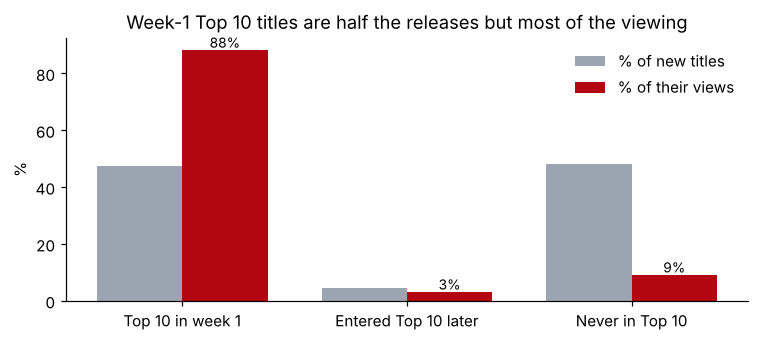

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(len(cov)); w = 0.38
ax.bar(x - w/2, cov.share_of_titles * 100, w, label='% of new titles', color='#9aa5b1')
ax.bar(x + w/2, cov.share_of_views * 100, w, label='% of their views', color='#b20710')
ax.set_xticks(x, cov.index); ax.set_ylabel('%'); ax.legend(frameon=False)
ax.set_title('Week-1 Top 10 titles are half the releases but most of the viewing')
for i, v in enumerate(cov.share_of_views * 100): ax.text(i + w/2, v + 1, f'{v:.0f}%', ha='center', fontsize=9)
plt.tight_layout(); plt.savefig('charts/1_coverage.png'); plt.show()

## 3. The analysis sample

To compare like with like, keep titles that:
- were in the Top 10 in their release week (so week 1 is known), and
- had **at least 91 days** left in the report window (so the outcome covers 3–6 months).

Live sports and WWE episodes are kept as their own group: people watch them live, so they behave differently.

In [5]:
s = df[(df.status == 'Top 10 in week 1') & (df.days_in_window >= 91)].copy()
s['mult'] = s.views / s.wk1_views          # how many times week 1 the title ends up with
s['log_wk1'] = np.log(s.wk1_views.astype(float))
s['log_views'] = np.log(s.views.astype(float))
s['log_days_left'] = np.log(s.days_in_window.astype(float))
print(len(s), 'titles')
s.segment.value_counts()

430 titles


segment
TV / Non-English      125
TV / English          123
Film / Non-English     93
Film / English         50
Live sports & WWE      39
Name: count, dtype: int64

## 4. Does week 1 rank titles correctly?

Spearman rank correlation: 1 = week 1 puts titles in exactly the same order as their half-year views.

In [6]:
def rank_corr(g):
    return pd.Series({'titles': len(g), 'spearman': round(spearmanr(g.wk1_views, g.views)[0], 2)})

order = ['Film / English', 'Film / Non-English', 'TV / English', 'TV / Non-English', 'Live sports & WWE']
rc = s.groupby('segment').apply(rank_corr, include_groups=False).loc[order]
rc.loc['All'] = [len(s), round(spearmanr(s.wk1_views, s.views)[0], 2)]
rc

,titles,spearman
segment,,
Film / English,50.0,0.95
Film / Non-English,93.0,0.88
TV / English,123.0,0.89
TV / Non-English,125.0,0.79
Live sports & WWE,39.0,0.96
All,430.0,0.83


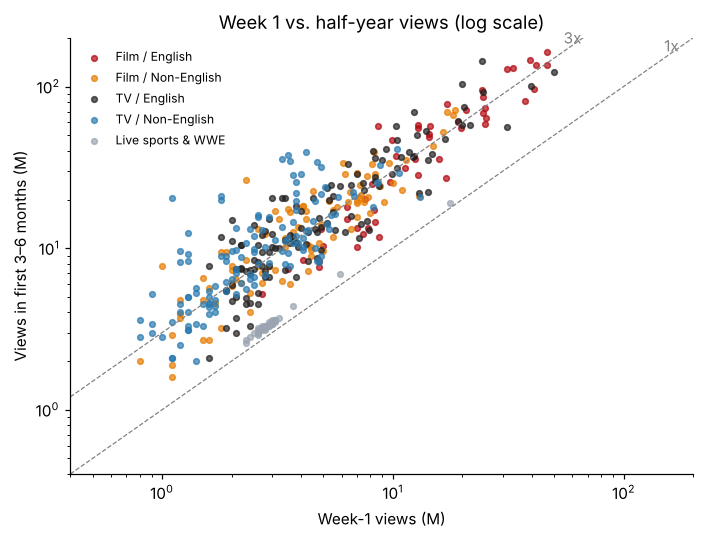

In [7]:
colors = dict(zip(order, ['#b20710', '#e87c03', '#221f1f', '#2a7ab0', '#9aa5b1']))
fig, ax = plt.subplots(figsize=(6.5, 5))
for seg in order:
    g = s[s.segment == seg]
    ax.scatter(g.wk1_views / 1e6, g.views / 1e6, s=14, alpha=.7, label=seg, color=colors[seg])
lim = [0.4, 200]
for k in (1, 3): ax.plot(lim, [l * k for l in lim], ls='--', lw=.8, color='grey')
ax.text(150, 165, '1x', color='grey'); ax.text(55, 185, '3x', color='grey')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('Week-1 views (M)'); ax.set_ylabel('Views in first 3–6 months (M)')
ax.set_title('Week 1 vs. half-year views (log scale)'); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig('charts/2_scatter.png'); plt.show()

## 5. How noisy is it? The multiplier

Multiplier = half-year views ÷ week-1 views. If it were stable, week 1 would be a great forecast. The spread (10th to 90th percentile) is the noise you live with.

In [8]:
q = s.groupby('segment').mult.quantile([.1, .5, .9]).unstack().loc[order].round(1)
q.columns = ['p10', 'median', 'p90']
q['p90 / p10'] = (q.p90 / q.p10).round(1)
q

,p10,median,p90,p90 / p10
segment,,,,
Film / English,1.7,2.8,4.2,2.5
Film / Non-English,1.9,3.0,4.8,2.5
TV / English,1.9,3.1,5.1,2.7
TV / Non-English,2.4,3.3,7.0,2.9
Live sports & WWE,1.1,1.2,1.2,1.1


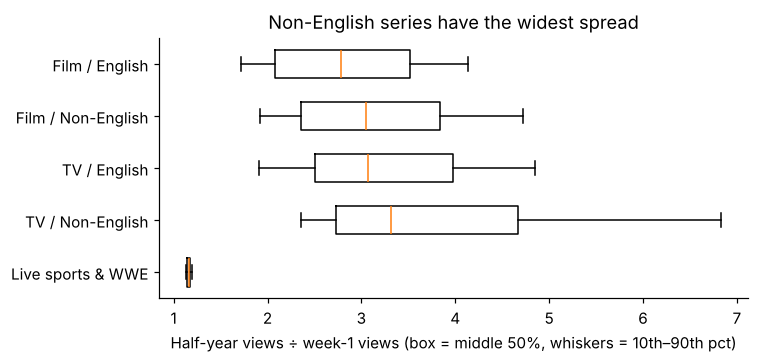

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.4))
data = [s.loc[s.segment == seg, 'mult'] for seg in order]
ax.boxplot(data, orientation='horizontal', whis=(10, 90), showfliers=False, widths=.55)
ax.set_yticks(range(1, len(order) + 1), order); ax.invert_yaxis()
ax.set_xlabel('Half-year views ÷ week-1 views (box = middle 50%, whiskers = 10th–90th pct)')
ax.set_title('Non-English series have the widest spread')
plt.tight_layout(); plt.savefig('charts/3_multiplier.png'); plt.show()

## 6. A hidden bias: days live in week 1

Netflix weeks run Monday to Sunday. A Friday release gets 3 days in "week 1", while a Monday release gets 7. Raw week-1 views punish late-week releases.

In [10]:
nl = s[~s.live]
dl = nl.groupby('days_live_wk1').agg(titles=('title', 'size'), median_mult=('mult', 'median')).round(2)
dl

,titles,median_mult
days_live_wk1,,
2.0,9,3.33
3.0,118,3.75
4.0,102,3.36
5.0,97,2.76
6.0,48,2.09
7.0,17,2.13


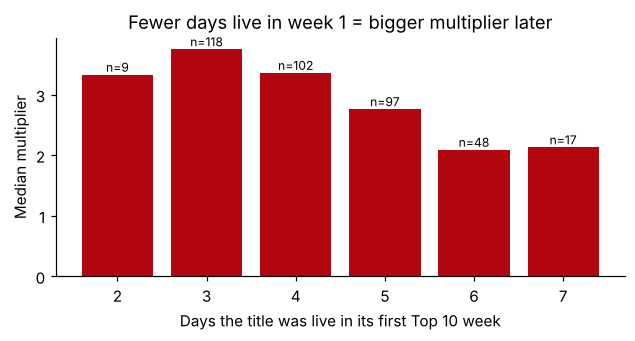

In [11]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(dl.index.astype(int).astype(str), dl.median_mult, color='#b20710')
for i, (n, v) in enumerate(zip(dl.titles, dl.median_mult)): ax.text(i, v + .05, f'n={n}', ha='center', fontsize=8)
ax.set_xlabel('Days the title was live in its first Top 10 week'); ax.set_ylabel('Median multiplier')
ax.set_title('Fewer days live in week 1 = bigger multiplier later')
plt.tight_layout(); plt.savefig('charts/4_days_live.png'); plt.show()

### One pair as an illustration

Two English series with almost the same half-year views, released on different weekdays (used in the blog post; one pair is an example, not evidence).

In [12]:
pair = s[s.title.isin(['Leanne: Season 1', 'Homicide: Los Angeles'])].copy()
pair['weekday'] = pair.release.dt.day_name()
pair[['title', 'release', 'weekday', 'days_live_wk1', 'wk1_views', 'views', 'days_in_window']]

,title,release,weekday,days_live_wk1,wk1_views,views,days_in_window
53,Homicide: Los Angeles,2024-07-16,Tuesday,6.0,4300000.0,12500000.0,169
943,Leanne: Season 1,2025-07-31,Thursday,4.0,2700000.0,12000000.0,154


## 7. Out-of-sample test

Can we turn week 1 into a usable forecast? Train on Jul 2024 – Dec 2025 (3 half-years), test on Jan – Jun 2026.

- **A. One multiplier:** week 1 × the median multiplier from training.
- **B. Multiplier by segment:** same, but one median per segment.
- **C. Regression:** log(views) on log(week 1) + segment + days live in week 1 + log(days left in window).

Error = |forecast − actual| ÷ actual.

In [13]:
tr, te = s[s.half != '2026H1'].copy(), s[s.half == '2026H1'].copy()
print(len(tr), 'train titles,', len(te), 'test titles')

te['A'] = te.wk1_views * tr.mult.median()
te['B'] = te.wk1_views * te.segment.map(tr.groupby('segment').mult.median())
fit = smf.ols('log_views ~ log_wk1 + C(segment) + days_live_wk1 + log_days_left', data=tr).fit()
te['C'] = np.exp(fit.predict(te))
# Bias check: exp() of a log-model forecast gives a median, so we compare medians of errors.

def score(pred):
    ape = (te[pred] - te.views).abs() / te.views
    return pd.Series({'median abs % error': round(ape.median() * 100, 1),
                      '% within ±25%': round((ape <= .25).mean() * 100, 1),
                      'spearman': round(spearmanr(te[pred], te.views)[0], 2)})

res = pd.DataFrame({'A. One multiplier': score('A'), 'B. By segment': score('B'), 'C. Regression': score('C')}).T
res

326 train titles, 104 test titles


,median abs % error,% within ±25%,spearman
A. One multiplier,32.2,44.2,0.82
B. By segment,20.9,55.8,0.90
C. Regression,18.8,56.7,0.91


In [14]:
# Fit check: train vs. test error for the regression (overfitting shows as a big gap)
tr['C'] = np.exp(fit.predict(tr))
for name, d in [('train', tr), ('test', te)]:
    print(name, 'median abs % error:', round(((d.C - d.views).abs() / d.views).median() * 100, 1))
print(fit.params.round(3))

train median abs % error: 17.3
test median abs % error: 18.8
Intercept                           1.331
C(segment)[T.Film / Non-English]    0.074
C(segment)[T.Live sports & WWE]    -0.430
C(segment)[T.TV / English]          0.227
C(segment)[T.TV / Non-English]      0.326
log_wk1                             1.001
days_live_wk1                      -0.167
log_days_left                       0.072
dtype: float64


### 7b. Which fix does the work?

Added Nov 24, 2026, after the first write-up. Forecast C uses two fixes at once: content segment and days live in week 1. Here each one is tested alone, on the same train/test split.

In [15]:
# Each fix alone vs. both together (same train/test split as above)
def score_pred(p):
    e = (p - te.views).abs() / te.views
    return pd.Series({'median abs % error': round(e.median() * 100, 1), '% within ±25%': round((e <= .25).mean() * 100, 1)})

dl_mult = tr.groupby('days_live_wk1').mult.median()      # one multiplier per days-live value
split = pd.DataFrame({
    'A. One multiplier': score_pred(te.wk1_views * tr.mult.median()),
    'D. Multiplier by days live': score_pred(te.wk1_views * te.days_live_wk1.map(dl_mult)),
    'B. Multiplier by segment': score_pred(te.B),
    'C. Regression (both)': score_pred(te.C),
}).T
split

,median abs % error,% within ±25%
A. One multiplier,32.2,44.2
D. Multiplier by days live,22.9,56.7
B. Multiplier by segment,20.9,55.8
C. Regression (both),18.8,56.7


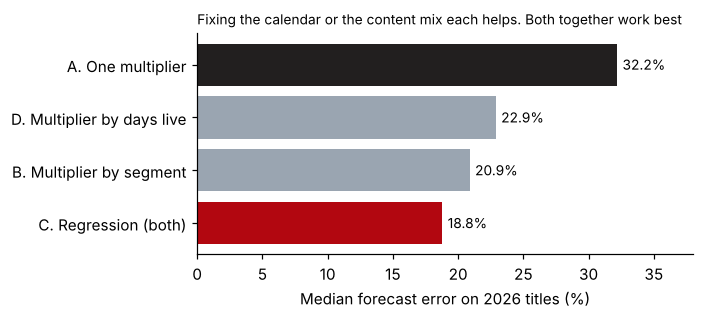

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.barh(split.index[::-1], split['median abs % error'][::-1], color=['#b20710', '#9aa5b1', '#9aa5b1', '#221f1f'])
for i, v in enumerate(split['median abs % error'][::-1]): ax.text(v + .4, i, f'{v:.1f}%', va='center', fontsize=9)
ax.set_xlabel('Median forecast error on 2026 titles (%)'); ax.set_xlim(0, 38)
ax.set_title('Fixing the calendar or the content mix each helps. Both together work best', fontsize=9, loc='left')
plt.tight_layout(); plt.savefig('charts/5_forecast_error.png', dpi=200); plt.show()

## 8. What the proxy misses

Among new releases with 91+ days in the window, take the top 25% by half-year views. How many were **not** in the Top 10 in their release week, so a week-1 rule would never have flagged them?

In [17]:
pool = df[df.days_in_window >= 91].copy()
top = pool[pool.views >= pool.views.quantile(.75)]
miss = top.status.value_counts(normalize=True).round(3)
print(len(top), 'top-quartile titles'); print(miss)
top[top.status != 'Top 10 in week 1'].sort_values('views', ascending=False)[['title', 'type', 'release', 'views', 'status']].head(10)

229 top-quartile titles
status
Top 10 in week 1        0.969
Entered Top 10 later    0.022
Never in Top 10         0.009
Name: proportion, dtype: float64


,title,type,release,views,status
411,SAKAMOTO DAYS: Season 1,TV,2025-01-11,24400000.0,Entered Top 10 later
1407,KPop Demon Hunters Bonus Content: Fan Collection,TV,2026-03-06,18000000.0,Never in Top 10
827,Wallace & Gromit: Vengeance Most Fowl,Film,2025-01-03,17300000.0,Entered Top 10 later
39,CoComelon Lane: Season 3,TV,2024-08-19,15700000.0,Never in Top 10
832,Love Forever // Kärlek fårever,Film,2025-02-14,15600000.0,Entered Top 10 later
310,Inside the Mind of a Dog,Film,2024-08-09,12900000.0,Entered Top 10 later
949,The Fragrant Flower Blooms With Dignity: Seaso...,TV,2025-07-05,11100000.0,Entered Top 10 later


## 9. Takeaways

See `README.md` for the write-up. In short:
1. Week 1 is a **strong ranking proxy for films** and a weaker one for series.
2. It is a **noisy forecast**: the multiplier spread is wide, especially for non-English series.
3. **Days live in week 1** is a built-in bias that's easy to correct. With the correction and a split by segment, forecast error falls from ~32% to ~19%.
4. It **rarely misses big hits**: half of new releases never reach the Top 10, but they are small. Only ~3% of the top 25% of titles started outside it.
5. **Live events** need their own metric: almost all their viewing happens in week 1.

**Limits:** only titles that hit the global Top 10 have weekly views. The half-year window runs 91–184 days, depending on release date. Views are rounded by Netflix. A few renamed titles may still be unmatched.